# 1. Prepare hourly demand data

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"D:\HCL_PROJECTS\EV_Charging_Demand_Analysis\ChargingRecords_preprocessed.csv")

df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="coerce"
)
df["Demand"] = pd.to_numeric(df["Demand"], errors="coerce")

df = df.dropna(subset=["StartDatetime", "Demand"])
df = df.sort_values("StartDatetime")

# Aggregate demand by hour
hourly_demand = (
    df.set_index("StartDatetime")["Demand"]
      .resample("h")
      .sum()
)

# Fill missing hours only if they represent zero demand
hourly_demand = hourly_demand.asfreq("h", fill_value=0)

print(hourly_demand.head())

StartDatetime
2021-09-30 17:00:00     27.68
2021-09-30 18:00:00     93.58
2021-09-30 19:00:00     30.17
2021-09-30 20:00:00     47.00
2021-09-30 21:00:00    117.54
Freq: h, Name: Demand, dtype: float64


# 2. Analyze trend and seasonality

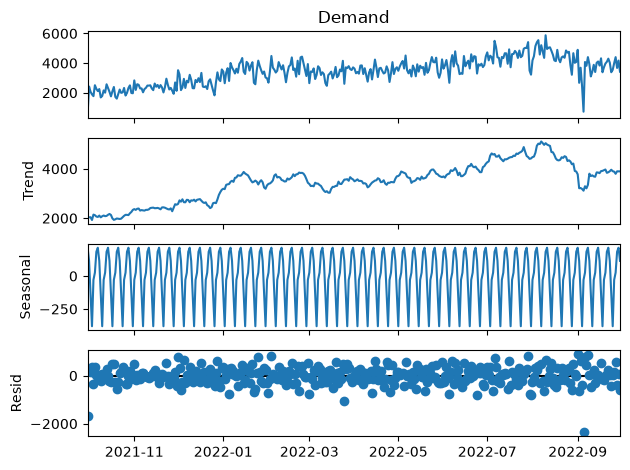

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Aggregate hourly data into daily demand
daily_demand = hourly_demand.resample("D").sum()

decomposition = seasonal_decompose(
    daily_demand,
    model="additive",
    period=7,
    extrapolate_trend="freq"
)

decomposition.plot()
plt.tight_layout()
plt.show()

# 3. Test stationarity

In [7]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(daily_demand.dropna())

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] < 0.05:
    print("The series provides evidence against a unit root.")
else:
    print("The series may be non-stationary.")

ADF Statistic: -1.8692206831481908
p-value: 0.3466762752416386
The series may be non-stationary.


# 4. Forecast using Moving Average and Exponential Smoothing

In [8]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing
)

series = daily_demand.astype(float).dropna()

split = int(len(series) * 0.8)
train = series.iloc[:split]
test = series.iloc[split:]

if len(train) < 7:
    raise ValueError("At least 7 training days are needed.")

# Moving Average: recursive 7-day forecast
history = train.tolist()
ma_forecast = []

for _ in range(len(test)):
    prediction = np.mean(history[-7:])
    ma_forecast.append(prediction)
    history.append(prediction)

# Simple Exponential Smoothing
ses_model = SimpleExpSmoothing(
    train,
    initialization_method="estimated"
).fit(optimized=True)

ses_forecast = ses_model.forecast(len(test))

# Holt-Winters with weekly seasonality
hw_forecast = None

if len(train) >= 21:
    hw_model = ExponentialSmoothing(
        train,
        trend="add",
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated"
    ).fit(optimized=True)

    hw_forecast = hw_model.forecast(len(test))

# Evaluation
def evaluate(name, actual, predicted):
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(actual, predicted), 3))
    print("RMSE:", round(
        np.sqrt(mean_squared_error(actual, predicted)), 3
    ))

evaluate("Moving Average", test, ma_forecast)
evaluate("Simple Exponential Smoothing", test, ses_forecast)

if hw_forecast is not None:
    evaluate("Holt-Winters", test, hw_forecast)


Moving Average
MAE: 571.135
RMSE: 791.737

Simple Exponential Smoothing
MAE: 572.757
RMSE: 792.651

Holt-Winters
MAE: 797.053
RMSE: 1037.134


# 5. Plot the forecasts

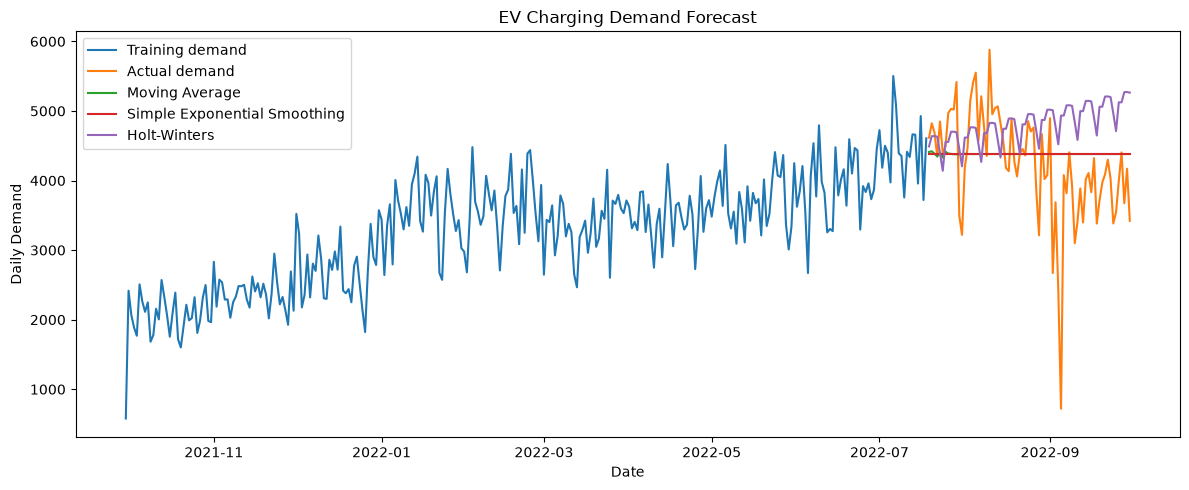

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Training demand")
plt.plot(test.index, test, label="Actual demand")
plt.plot(test.index, ma_forecast, label="Moving Average")
plt.plot(test.index, ses_forecast, label="Simple Exponential Smoothing")

if hw_forecast is not None:
    plt.plot(test.index, hw_forecast, label="Holt-Winters")

plt.title("EV Charging Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Demand")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
pip install statsmodels scikit-learn xgboost prophet

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.1 MB 3.7 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/12.1 MB 3.3 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/12.1 MB 3.6 MB/s eta 0:00:03
   --------- ------------------------------ 2.9/12.1 MB 3.7 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/12.1 MB 3.8 MB/s eta 0:00:03
   --------------- ------------------------ 4.7/12.1 MB 3.9 MB/s eta 0:00:02
   ------------------- -------------------- 5.8/12.1 MB 4.0 MB/s eta 0:00:02
   ---------------------- ----------------- 6.8/12.1 MB 4.1 MB/s eta 0:00:02
   ------------------------- -------------- 7.6/12.1 MB 4.2 MB/s eta 0:00:02
   ---------------------------- ----------- 8.7/12.1 MB 4.3 MB/s eta 0:00:01
   -------------------------------- ------- 9.7/12.1 MB 4.3 MB/s eta 0:00:01
   --


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\VIDYAPRIYA V\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# 2. Prepare the time series

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"D:\HCL_PROJECTS\EV_Charging_Demand_Analysis\ChargingRecords_preprocessed.csv")

df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="coerce"
)
df["Demand"] = pd.to_numeric(df["Demand"], errors="coerce")

df = df.dropna(subset=["StartDatetime", "Demand"])
df = df.sort_values("StartDatetime")

daily = (
    df.set_index("StartDatetime")["Demand"]
      .resample("D")
      .sum()
)

# Use zero only for dates known to have no demand.
daily = daily.asfreq("D", fill_value=0).astype(float)

# Chronological 80/20 split
split = int(len(daily) * 0.8)
train = daily.iloc[:split]
test = daily.iloc[split:]

print("Total observations:", len(daily))
print("Training observations:", len(train))
print("Testing observations:", len(test))

Total observations: 366
Training observations: 292
Testing observations: 74


# 3. Advanced Model 1 — SARIMA

In [13]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

sarima = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima.fit(disp=False)

sarima_pred = sarima_fit.forecast(steps=len(test))
sarima_pred.index = test.index

def evaluate(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (
        np.abs(np.asarray(actual) - np.asarray(predicted)).sum()
        / max(np.abs(np.asarray(actual)).sum(), 1e-8)
        * 100
    )

    print(f"\n{name}")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"WAPE: {wape:.2f}%")

evaluate("SARIMA", test, sarima_pred)


SARIMA
MAE:  778.6284
RMSE: 1015.4934
WAPE: 18.41%


# 4. Advanced Model 2 — SARIMAX with external variables

In [14]:
def make_calendar(index):
    features = pd.DataFrame(index=index)
    features["day_of_week"] = index.dayofweek
    features["is_weekend"] = (index.dayofweek >= 5).astype(int)
    features["month"] = index.month
    features["day_of_year_sin"] = np.sin(
        2 * np.pi * index.dayofyear / 365.25
    )
    features["day_of_year_cos"] = np.cos(
        2 * np.pi * index.dayofyear / 365.25
    )
    return features

X_train = make_calendar(train.index)
X_test = make_calendar(test.index)

sarimax = SARIMAX(
    train,
    exog=X_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax.fit(disp=False)

sarimax_pred = sarimax_fit.get_forecast(
    steps=len(test),
    exog=X_test
).predicted_mean

sarimax_pred.index = test.index

evaluate("SARIMAX", test, sarimax_pred)


SARIMAX
MAE:  1650.3821
RMSE: 2032.0673
WAPE: 39.01%


# 5. Advanced Model 3 — XGBoost with lag features

In [15]:
from xgboost import XGBRegressor

def make_features(series):
    data = pd.DataFrame(index=series.index)
    data["demand"] = series

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = series.shift(lag)

    data["rolling_mean_7"] = series.shift(1).rolling(7).mean()
    data["rolling_mean_14"] = series.shift(1).rolling(14).mean()
    data["day_of_week"] = series.index.dayofweek
    data["month"] = series.index.month
    data["is_weekend"] = (
        series.index.dayofweek >= 5
    ).astype(int)

    return data.dropna()

features = make_features(daily)

# Split by date to avoid leakage
train_features = features.loc[features.index < test.index[0]]
X = train_features.drop(columns="demand")
y = train_features["demand"]

xgb = XGBRegressor(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X, y)

# Recursive multi-step forecast: never use actual future demand
history = daily.loc[:train.index[-1]].copy()
xgb_predictions = []

for date in test.index:
    row = pd.DataFrame(index=[date])

    for lag in [1, 2, 3, 7, 14, 28]:
        row[f"lag_{lag}"] = history.iloc[-lag]

    row["rolling_mean_7"] = history.iloc[-7:].mean()
    row["rolling_mean_14"] = history.iloc[-14:].mean()
    row["day_of_week"] = date.dayofweek
    row["month"] = date.month
    row["is_weekend"] = int(date.dayofweek >= 5)

    prediction = xgb.predict(row[X.columns])[0]

    xgb_predictions.append(prediction)
    history.loc[date] = prediction

xgb_pred = pd.Series(xgb_predictions, index=test.index)

evaluate("XGBoost with lag features", test, xgb_pred)


XGBoost with lag features
MAE:  584.4602
RMSE: 791.1588
WAPE: 13.82%


# 6. Advanced Model 4 — Prophet

21:20:59 - cmdstanpy - INFO - Chain [1] start processing
21:21:00 - cmdstanpy - INFO - Chain [1] done processing



Prophet
MAE:  693.2613
RMSE: 898.0863
WAPE: 16.39%


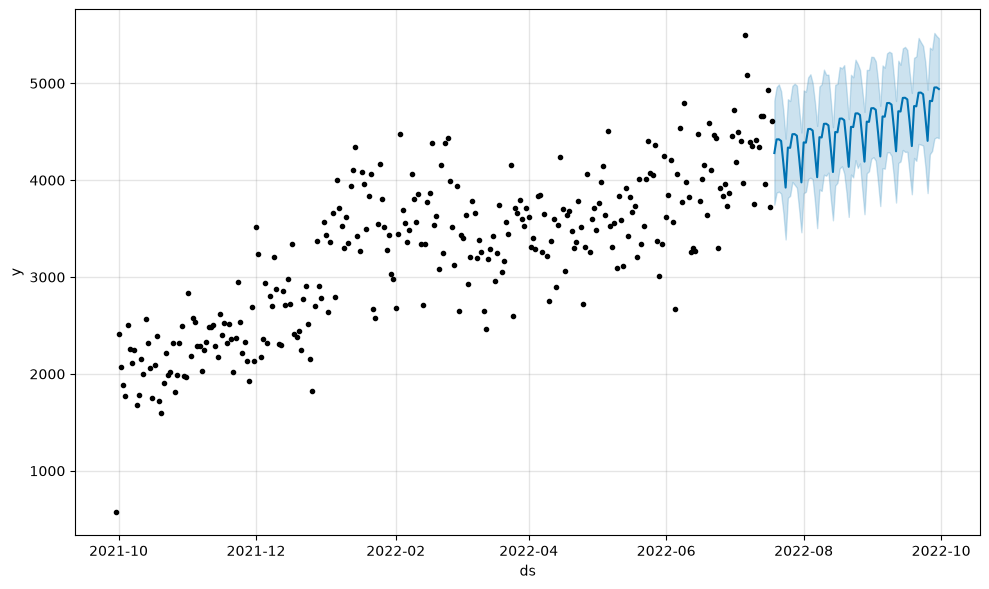

In [16]:
from prophet import Prophet

prophet_train = train.rename_axis("ds").reset_index()
prophet_train.columns = ["ds", "y"]

prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality="auto",
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

future = pd.DataFrame({"ds": test.index})
prophet_result = prophet_model.predict(future)

prophet_pred = pd.Series(
    prophet_result["yhat"].to_numpy(),
    index=test.index
)

evaluate("Prophet", test, prophet_pred)

prophet_model.plot(prophet_result)
plt.tight_layout()
plt.show()

# 7. Compare all models

In [17]:
predictions = {
    "SARIMA": sarima_pred,
    "SARIMAX": sarimax_pred,
    "XGBoost": xgb_pred,
    "Prophet": prophet_pred,
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(test, pred),
        "RMSE": np.sqrt(mean_squared_error(test, pred)),
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]["Model"]
print("\nBest model by RMSE:", best_model_name)

  Model         MAE        RMSE
XGBoost  584.460160  791.158812
Prophet  693.261309  898.086308
 SARIMA  778.628370 1015.493365
SARIMAX 1650.382068 2032.067340

Best model by RMSE: XGBoost


# 8. Plot the final comparison

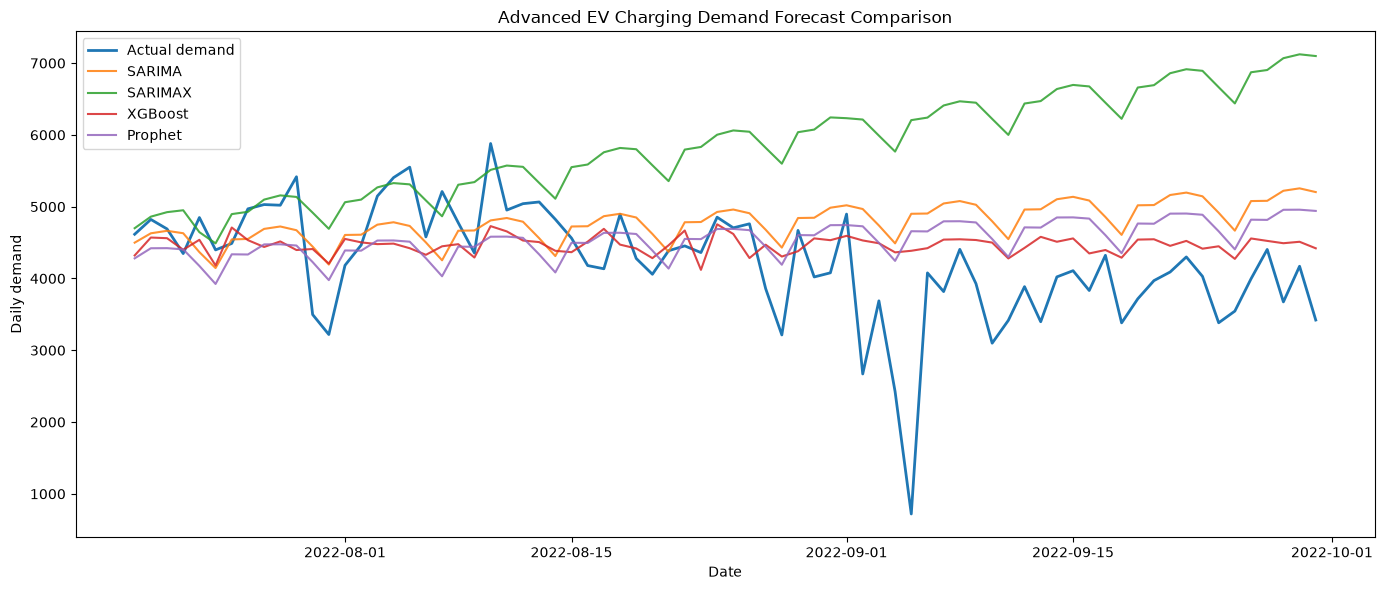

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(test.index, test, label="Actual demand", linewidth=2)

for name, pred in predictions.items():
    plt.plot(test.index, pred, label=name, alpha=0.85)

plt.title("Advanced EV Charging Demand Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Daily demand")
plt.legend()
plt.tight_layout()
plt.show()